1. Eksperimen Skala


Eksperimen ini mengambil metadata dari 25 paket PyPI. Permintaan HTTP dijalankan secara asynchronous dengan bantuan asyncio.to_thread() agar operasi jaringan yang blocking berlangsung di thread pekerja, bukan memblokir event loop. asyncio.Semaphore membatasi jumlah permintaan yang berjalan bersamaan.

Paket yang dipilih antara lain requests, numpy, pandas, flask, django, dan paket populer lain. Jika PyPI sedang lambat atau koneksi internet tidak tersedia, beberapa permintaan mungkin gagal; program akan mencatat kegagalan dan tetap melanjutkan.

In [1]:
import asyncio
import json
import time
import urllib.request
import urllib.error
import matplotlib.pyplot as plt

daftar_paket_banyak = [
    "requests", "numpy", "pandas", "matplotlib", "scipy",
    "flask", "django", "fastapi", "uvicorn", "pytest",
    "beautifulsoup4", "pillow", "scikit-learn", "torch", "tensorflow",
    "sqlalchemy", "pydantic", "httpx", "aiohttp", "rich",
    "jupyter", "ipython", "streamlit", "selenium", "cryptography"
]

BATAS_KONKURENSI = 5

Fungsi pengambilan metadata

Setiap paket diakses melalui endpoint JSON resmi PyPI. Fungsi ambil_metadata() menggunakan urllib untuk membaca respons, sedangkan asyncio.to_thread() memindahkan fungsi tersebut ke thread pekerja. Semaphore memastikan jumlah permintaan aktif tidak melampaui batas yang sedang diuji.

In [2]:
def ambil_metadata_sync(nama_paket):
    url = f"https://pypi.org/pypi/{nama_paket}/json"
    request = urllib.request.Request(
        url,
        headers={"User-Agent": "TugasPraktikumAsyncio/1.0"}
    )
    with urllib.request.urlopen(request, timeout=15) as response:
        data = json.loads(response.read().decode("utf-8"))
    info = data.get("info", {})
    return {
        "nama": nama_paket,
        "versi": info.get("version", "tidak diketahui"),
        "deskripsi": (info.get("summary") or "")[:100]
    }

async def ambil_metadata(nama_paket, semaphore):
    async with semaphore:
        try:
            hasil = await asyncio.to_thread(ambil_metadata_sync, nama_paket)
            return hasil
        except Exception as e:
            return {"nama": nama_paket, "error": str(e)}

async def jalankan_eksperimen(batas_konkuren):
    semaphore = asyncio.Semaphore(batas_konkuren)
    mulai = time.perf_counter()
    hasil = await asyncio.gather(
        *(ambil_metadata(nama, semaphore) for nama in daftar_paket_banyak)
    )
    durasi = time.perf_counter() - mulai
    berhasil = sum(1 for item in hasil if "versi" in item)
    gagal = len(hasil) - berhasil
    return durasi, berhasil, gagal, hasil

# Tes satu kali terlebih dahulu dengan batas konkurensi 5
durasi, berhasil, gagal, hasil = await jalankan_eksperimen(5)
print(f"Waktu total: {durasi:.2f} detik")
print(f"Berhasil: {berhasil}, gagal: {gagal}")
for item in hasil:
    if "versi" in item:
        print(f'{item["nama"]}: {item["versi"]}')
    else:
        print(f'{item["nama"]}: gagal — {item["error"]}')

Waktu total: 27.74 detik
Berhasil: 20, gagal: 5
requests: gagal — <urlopen error [Errno 11001] getaddrinfo failed>
numpy: gagal — <urlopen error [Errno 11001] getaddrinfo failed>
pandas: gagal — <urlopen error [Errno 11001] getaddrinfo failed>
matplotlib: gagal — <urlopen error [Errno 11001] getaddrinfo failed>
scipy: gagal — <urlopen error [Errno 11001] getaddrinfo failed>
flask: 3.1.3
django: 6.1.2
fastapi: 0.143.2
uvicorn: 0.54.0
pytest: 9.1.1
beautifulsoup4: 4.15.0
pillow: 12.3.0
scikit-learn: 1.9.1
torch: 2.14.1
tensorflow: 2.21.0
sqlalchemy: 2.1.4
pydantic: 2.14.1
httpx: 0.28.1
aiohttp: 3.14.5
rich: 15.0.0
jupyter: 1.1.1
ipython: 9.17.1
streamlit: 1.66.0
selenium: 4.51.0
cryptography: 50.0.2


Membandingkan batas konkurensi 1, 3, 5, 10, dan 20
Setiap nilai dijalankan satu kali untuk mengurangi waktu tunggu. Hasil waktu dapat berubah-ubah karena latensi jaringan, cache, pembatasan permintaan server, dan kondisi komputer. Jika hasil sangat tidak stabil, jalankan ulang eksperimen atau lakukan beberapa pengulangan lalu gunakan rata-rata.

In [3]:
daftar_batas = [1, 3, 5, 10, 20]
hasil_eksperimen = []

for batas in daftar_batas:
    durasi, berhasil, gagal, _ = await jalankan_eksperimen(batas)
    hasil_eksperimen.append({
        "batas": batas,
        "waktu": durasi,
        "berhasil": berhasil,
        "gagal": gagal
    })
    print(
        f"Batas={batas:>2} | waktu={durasi:6.2f} detik | "
        f"berhasil={berhasil} | gagal={gagal}"
    )

Batas= 1 | waktu= 46.55 detik | berhasil=25 | gagal=0
Batas= 3 | waktu= 17.38 detik | berhasil=11 | gagal=14
Batas= 5 | waktu=  0.28 detik | berhasil=0 | gagal=25
Batas=10 | waktu=  0.15 detik | berhasil=0 | gagal=25
Batas=20 | waktu=  0.12 detik | berhasil=0 | gagal=25


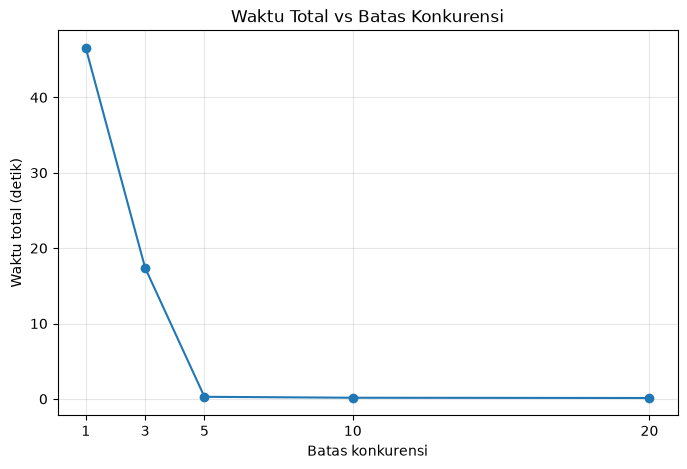

Tabel hasil:
Batas  1: 46.55 detik (25 berhasil, 0 gagal)
Batas  3: 17.38 detik (11 berhasil, 14 gagal)
Batas  5: 0.28 detik (0 berhasil, 25 gagal)
Batas 10: 0.15 detik (0 berhasil, 25 gagal)
Batas 20: 0.12 detik (0 berhasil, 25 gagal)


In [4]:
x = [item["batas"] for item in hasil_eksperimen]
y = [item["waktu"] for item in hasil_eksperimen]

plt.figure(figsize=(8, 5))
plt.plot(x, y, marker="o")
plt.title("Waktu Total vs Batas Konkurensi")
plt.xlabel("Batas konkurensi")
plt.ylabel("Waktu total (detik)")
plt.xticks(daftar_batas)
plt.grid(True, alpha=0.3)
plt.show()

print("Tabel hasil:")
for item in hasil_eksperimen:
    print(
        f'Batas {item["batas"]:>2}: {item["waktu"]:.2f} detik '
        f'({item["berhasil"]} berhasil, {item["gagal"]} gagal)'
    )

Analisis eksperimen skala
Isi analisis berdasarkan angka dan grafik yang muncul setelah notebook dijalankan.
- Ketika batas konkurensi naik dari 1 ke 3 atau 5, waktu total biasanya berkurang karena beberapa permintaan jaringan dapat berlangsung bersamaan.
- Kenaikan dari 10 ke 20 belum tentu memberi peningkatan yang besar. Pada titik tertentu, waktu lebih banyak dipengaruhi latensi jaringan, waktu respons PyPI, pembatasan server, dan overhead pengelolaan tugas.
- Diminishing returns terjadi ketika penambahan batas konkurensi hanya mempercepat proses sedikit dibandingkan kenaikan sebelumnya. Tentukan titiknya dari grafik aktual, yaitu saat kurva mulai mendatar; jangan menetapkan angka sebelum melihat hasil pengukuran.
- Hal ini berkaitan dengan Hukum Amdahl: peningkatan jumlah pekerjaan yang berjalan bersamaan tidak dapat mempercepat bagian proses yang tidak bisa diparalelkan. Dalam eksperimen ini, latensi jaringan, overhead, dan batas layanan menjadi faktor yang membatasi peningkatan kinerja.

2. Deteksi Blocking Call

Tiga coroutine berikut mewakili: (1) operasi asynchronous yang memakai asyncio.sleep(), (2) pemanggilan blocking time.sleep(), dan (3) pekerjaan CPU-bound yang tidak memiliki await. Coroutine keempat mencatat timestamp secara berkala untuk melihat apakah event loop masih dapat menjalankan tugas lain.

In [5]:
import asyncio
import time
import math

waktu_awal = None

def timestamp():
    return f"{time.perf_counter() - waktu_awal:5.2f} detik"

async def tugas_async_sleep():
    print(timestamp(), "- async_sleep mulai")
    await asyncio.sleep(2)
    print(timestamp(), "- async_sleep selesai")

async def tugas_time_sleep():
    print(timestamp(), "- time_sleep mulai (event loop akan terblokir)")
    time.sleep(2)
    print(timestamp(), "- time_sleep selesai")

async def tugas_cpu_bound():
    print(timestamp(), "- CPU-bound mulai")
    # Pekerjaan CPU murni tanpa await di dalam loop.
    total = 0
    for i in range(1, 2_000_000):
        total += i * i
    print(timestamp(), f"- CPU-bound selesai (hasil={total})")

async def pencatat_timestamp():
    for nomor in range(8):
        print(timestamp(), f"- pencatat ke-{nomor + 1}")
        await asyncio.sleep(0.5)

async def uji_blocking():
    global waktu_awal
    waktu_awal = time.perf_counter()
    await asyncio.gather(
        tugas_async_sleep(),
        tugas_time_sleep(),
        tugas_cpu_bound(),
        pencatat_timestamp()
    )

await uji_blocking()

 0.00 detik - async_sleep mulai
 0.00 detik - time_sleep mulai (event loop akan terblokir)
 2.00 detik - time_sleep selesai
 2.00 detik - CPU-bound mulai
 2.59 detik - CPU-bound selesai (hasil=2666664666667000000)
 2.59 detik - pencatat ke-1
 2.59 detik - async_sleep selesai
 3.09 detik - pencatat ke-2
 3.59 detik - pencatat ke-3
 4.11 detik - pencatat ke-4
 4.61 detik - pencatat ke-5
 5.12 detik - pencatat ke-6
 5.62 detik - pencatat ke-7
 6.13 detik - pencatat ke-8


Analisis blocking call

Perhatikan urutan timestamp pada output:
1. asyncio.sleep() memberi kesempatan kepada event loop untuk menjalankan coroutine lain selama menunggu. Karena itu, coroutine ini bersifat kooperatif.
2. time.sleep() menghentikan thread tempat event loop berjalan. Selama dua detik tersebut, coroutine lain—termasuk pencatat timestamp—tidak dapat dijadwalkan.
3. Loop CPU-bound juga tidak memberi kesempatan kepada event loop karena tidak memiliki await. Selama perhitungan berlangsung, coroutine lain tertunda sampai loop tersebut selesai.
4. asyncio.gather() tidak otomatis membuat kode menjadi paralel. Coroutine tetap berbagi satu event loop; tugas hanya bergantian berjalan ketika tugas yang aktif mencapai titik yang memungkinkan event loop berpindah.

3. Producer–Multi-Consumer dengan Prioritas
   
asyncio.PriorityQueue mengeluarkan elemen berdasarkan urutan prioritas terkecil terlebih dahulu. Karena angka 1 adalah prioritas tertinggi dan angka 3 terendah, setiap item disimpan sebagai tuple (prioritas, nomor_urut, nama_item). nomor_urut menjadi pemecah seri agar item dengan prioritas sama tetap dapat diurutkan secara konsisten.

In [6]:
import asyncio
import itertools

async def producer(queue):
    daftar_item = [
        (3, "Pekerjaan biasa A"),
        (1, "Pekerjaan darurat A"),
        (2, "Pekerjaan menengah A"),
        (3, "Pekerjaan biasa B"),
        (1, "Pekerjaan darurat B"),
        (2, "Pekerjaan menengah B"),
        (1, "Pekerjaan darurat C"),
        (3, "Pekerjaan biasa C"),
    ]

    nomor_urut = itertools.count()
    for prioritas, nama_item in daftar_item:
        await queue.put((prioritas, next(nomor_urut), nama_item))
        print(f"Producer memasukkan: prioritas={prioritas}, item={nama_item}")
        await asyncio.sleep(0.1)

    # Satu tanda berhenti untuk setiap consumer.
    for _ in range(3):
        await queue.put((99, next(nomor_urut), "STOP"))

async def consumer(nama_consumer, queue):
    while True:
        prioritas, nomor, nama_item = await queue.get()
        try:
            if nama_item == "STOP":
                print(f"{nama_consumer} berhenti")
                return

            print(
                f"{nama_consumer} memproses "
                f"(prioritas={prioritas}): {nama_item}"
            )
            await asyncio.sleep(0.4)
        finally:
            queue.task_done()

async def main_priority_queue():
    queue = asyncio.PriorityQueue()

    tugas_producer = asyncio.create_task(producer(queue))
    daftar_consumer = [
        asyncio.create_task(consumer(f"Consumer-{i}", queue))
        for i in range(1, 4)
    ]

    await tugas_producer
    await queue.join()
    await asyncio.gather(*daftar_consumer)

await main_priority_queue()

Producer memasukkan: prioritas=3, item=Pekerjaan biasa A
Consumer-1 memproses (prioritas=3): Pekerjaan biasa A
Producer memasukkan: prioritas=1, item=Pekerjaan darurat A
Consumer-2 memproses (prioritas=1): Pekerjaan darurat A
Producer memasukkan: prioritas=2, item=Pekerjaan menengah A
Consumer-3 memproses (prioritas=2): Pekerjaan menengah A
Producer memasukkan: prioritas=3, item=Pekerjaan biasa B
Consumer-1 memproses (prioritas=3): Pekerjaan biasa B
Producer memasukkan: prioritas=1, item=Pekerjaan darurat B
Consumer-2 memproses (prioritas=1): Pekerjaan darurat B
Producer memasukkan: prioritas=2, item=Pekerjaan menengah B
Consumer-3 memproses (prioritas=2): Pekerjaan menengah B
Producer memasukkan: prioritas=1, item=Pekerjaan darurat C
Producer memasukkan: prioritas=3, item=Pekerjaan biasa C
Consumer-1 memproses (prioritas=1): Pekerjaan darurat C
Consumer-2 memproses (prioritas=3): Pekerjaan biasa C
Consumer-3 berhenti
Consumer-1 berhenti
Consumer-2 berhenti


Analisis producer–multi-consumer

Producer memasukkan pekerjaan dengan prioritas 1, 2, dan 3. PriorityQueue mengambil item dengan angka prioritas paling kecil terlebih dahulu dari antrean yang tersedia. Tiga consumer mengambil pekerjaan dari antrean yang sama sehingga beberapa pekerjaan dapat diproses secara asynchronous.
Perlu diperhatikan bahwa prioritas berlaku pada item yang masih berada di antrean, bukan pekerjaan yang sudah telanjur diambil dan sedang diproses oleh consumer. Karena itu, jika consumer sedang mengerjakan item prioritas rendah ketika item prioritas tinggi baru masuk, item yang sedang berjalan tidak otomatis dihentikan. Pada contoh ini, STOP memakai prioritas 99 agar ditempatkan setelah pekerjaan biasa yang sudah masuk antrean.

4. Refleksi Singkat

Menurut saya, asynchronous I/O-bound cukup mudah dipahami setelah mencoba asyncio.gather(), asyncio.sleep(), dan PriorityQueue. Pada asynchronous, beberapa tugas bisa menunggu operasi I/O secara bersamaan tanpa harus membuat thread untuk setiap tugas. Namun, saya juga melihat bahwa kode blocking seperti time.sleep() atau perhitungan CPU tanpa await bisa menahan event loop dan membuat tugas lain terlambat berjalan.
Threading terasa cocok untuk pekerjaan yang perlu menunggu I/O, tetapi perlu memperhatikan akses bersama ke data. Multiprocessing lebih sesuai untuk pekerjaan CPU-bound karena proses dapat berjalan pada inti CPU yang berbeda, meskipun penggunaan memori dan komunikasi ant proses lebih rumit. Berdasarkan percobaan ini, asynchronous I/O-bound paling mudah saya pahami untuk tugas jaringan karena alur async dan await terlihat jelas. Untuk perhitungan berat, saya akan mempertimbangkan multiprocessing, bukan mengandalkan asyncio saja.